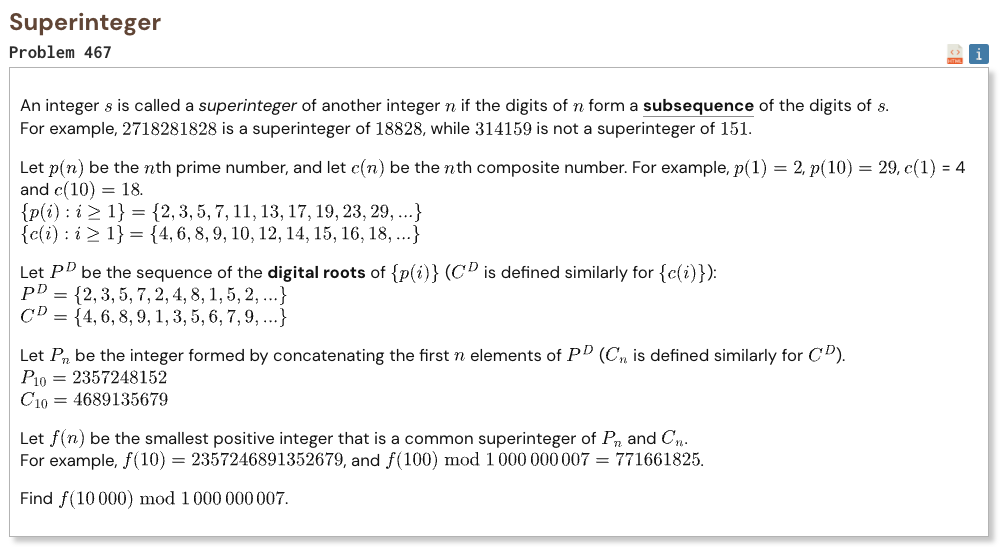

## Initial approach

-   generate the first 10000 primes and composite numbers, then replace each number with its digital root
-   the required number is the shortest common supersequence of the two digital root sequences
-   use dynamic programming to find the longest common subsequence from every pair of positions
-   matching digits are taken once because this keeps both sequences moving forward
-   when the digits differ, follow the direction that preserves the longer common subsequence
-   if both choices give the same minimum length, choose the smaller digit so the final number is also numerically smallest

In [1]:
%%time

from array import array
from math import isqrt

N = 10_000
MOD = 1_000_000_007
LIMIT = 120_000

def digital_root(n):
    return 1 + (n - 1) % 9

is_prime = bytearray(b"\x01") * (LIMIT + 1)
is_prime[0] = 0
is_prime[1] = 0

for p in range(2, isqrt(LIMIT) + 1):
    if is_prime[p]:
        start = p * p
        count = (LIMIT - start) // p + 1
        is_prime[start:LIMIT + 1:p] = b"\x00" * count

prime_digits = []
composite_digits = []

for number in range(2, LIMIT + 1):
    if is_prime[number]:
        if len(prime_digits) < N:
            prime_digits.append(digital_root(number))
    else:
        if len(composite_digits) < N:
            composite_digits.append(digital_root(number))

    if len(prime_digits) == N and len(composite_digits) == N:
        break

dp = [
    array("H", [0]) * (N + 1)
    for _ in range(N + 1)
]

for i in range(N - 1, -1, -1):
    current = dp[i]
    below = dp[i + 1]

    for j in range(N - 1, -1, -1):
        if prime_digits[i] == composite_digits[j]:
            current[j] = below[j + 1] + 1
        else:
            current[j] = max(
                below[j],
                current[j + 1]
            )

i = 0
j = 0
result = 0

while i < N or j < N:
    if i == N:
        digit = composite_digits[j]
        j += 1

    elif j == N:
        digit = prime_digits[i]
        i += 1

    elif prime_digits[i] == composite_digits[j]:
        digit = prime_digits[i]
        i += 1
        j += 1

    elif dp[i + 1][j] > dp[i][j + 1]:
        digit = prime_digits[i]
        i += 1

    elif dp[i + 1][j] < dp[i][j + 1]:
        digit = composite_digits[j]
        j += 1

    elif prime_digits[i] < composite_digits[j]:
        digit = prime_digits[i]
        i += 1

    else:
        digit = composite_digits[j]
        j += 1

    result = (result * 10 + digit) % MOD

print("Result:", result)

Result: 775181359
CPU times: user 19.4 s, sys: 110 ms, total: 19.5 s
Wall time: 19.5 s
